In [2]:
import pandas as pd

# 1. Define the file path (Make sure it matches your exact file name)
file_path = "ikonik_tableu.xlsx"

# 2. Read all sheets into a dictionary
print("Loading all sheets...")
all_sheets = pd.read_excel(file_path, sheet_name=None)

# 3. Extract the specific sheets needed for the ML model
df_patients = all_sheets['MASTER_Patients']
df_appointments = all_sheets['ADMIN_CS_Appointments']
df_payments = all_sheets['CASHIER_Payments']

# 4. Merge the DataFrames
# First, merge Appointments with Patient details using 'PatientID'
# We use how='left' to keep all appointment records
merged_df = pd.merge(df_appointments, df_patients, on='PatientID', how='left')

# Next, merge with Payments data (if needed) using 'PatientID' or 'AppointmentID'
# Note: Check if CASHIER_Payments has 'PatientID'. If it does, we can merge it.
merged_df = pd.merge(merged_df, df_payments, on='PatientID', how='left')

# 5. Check the columns and preview the merged data
print(f"\nMerged Data Shape (Rows, Columns): {merged_df.shape}")
print("\nColumns available for Machine Learning:")
print(merged_df.columns.tolist())

# Display the first 5 rows
display(merged_df.head())

Loading all sheets...

Merged Data Shape (Rows, Columns): (14145, 27)

Columns available for Machine Learning:
['ApptID', 'Date_x', 'Branch_x', 'PatientID', 'ApptType', 'DoctorID', 'BookingChannel', 'ReminderSent', 'Status', 'WaitTime_Min', 'CS_Agent', 'RegDate', 'Branch_y', 'AcquisitionChannel', 'ReceiptID', 'Date_y', 'Branch', 'CashierID', 'TreatmentID', 'Gross_RM', 'Discount_RM', 'NetBilled_RM', 'Collected_RM', 'PaymentMethod', 'Outstanding', 'Doctor', 'channel']


,ApptID,Date_x,Branch_x,PatientID,ApptType,DoctorID,BookingChannel,ReminderSent,Status,WaitTime_Min,...,CashierID,TreatmentID,Gross_RM,Discount_RM,NetBilled_RM,Collected_RM,PaymentMethod,Outstanding,Doctor,channel
0,A004212,2026-01-01 00:00:00,Puchong,P02470,Treatment,DR03,WhatsApp,Y,Attended,29,...,CA02,T003631,200.0,0.0,200.0,200.0,Card,0.0,DR03,Referral
1,A003672,2026-01-01 00:00:00,Puchong,P02249,Treatment,DR03,WhatsApp,N,No-Show,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,A003723,2026-01-01 00:00:00,Puchong,P02272,Treatment,DR04,WhatsApp,N,Attended,18,...,CA02,T003225,150.0,0.0,150.0,150.0,Card,0.0,DR04,Google Ads
3,A003723,2026-01-01 00:00:00,Puchong,P02272,Treatment,DR04,WhatsApp,N,Attended,18,...,CA02,T003226,360.0,0.0,360.0,360.0,Card,0.0,DR04,Google Ads
4,A000982,2026-01-01 00:00:00,Bangsar,P00513,Treatment,DR01,WhatsApp,Y,Attended,18,...,CA01,T000870,150.0,22.0,128.0,128.0,Panel Claim,0.0,DR01,Corporate Panel


In [3]:
import pandas as pd
import numpy as np

# 1. Replace NaN values in monetary columns with 0
# (Since No-Show patients bring zero revenue and have no outstanding debt)
monetary_cols = ['Gross_RM', 'Discount_RM', 'NetBilled_RM', 'Collected_RM', 'Outstanding']
for col in monetary_cols:
    merged_df[col] = merged_df[col].fillna(0)

# 2. Replace NaN values in categorical (text) columns with 'None'
# (No-Show patients won't have CashierID, TreatmentID, or a designated Doctor)
categorical_cols = ['CashierID', 'TreatmentID', 'PaymentMethod', 'Doctor', 'channel']
for col in categorical_cols:
    merged_df[col] = merged_df[col].fillna('None')

# 3. Create the Target Variable 'Is_No_Show' for Machine Learning
# If Status is 'No-Show', set value to 1 (True). Otherwise, 0 (False).
merged_df['Is_No_Show'] = np.where(merged_df['Status'] == 'No-Show', 1, 0)

# 4. Display the specific columns to verify the cleaning process
cols_to_check = ['Status', 'Is_No_Show', 'CashierID', 'Gross_RM', 'Collected_RM']
display(merged_df[cols_to_check].head(15))

,Status,Is_No_Show,CashierID,Gross_RM,Collected_RM
0,Attended,0,CA02,200.0,200.0
1,No-Show,1,None,0.0,0.0
2,Attended,0,CA02,150.0,150.0
3,Attended,0,CA02,360.0,360.0
4,Attended,0,CA01,150.0,128.0
5,Attended,0,CA01,150.0,128.0
6,Attended,0,CA02,80.0,80.0
7,Attended,0,CA02,150.0,135.0
8,Attended,0,CA02,80.0,80.0
9,Attended,0,CA02,7500.0,1500.0


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Select Features (X) and Target (y)
# Choose columns that exist BEFORE the appointment to predict No-Show
# Make sure these columns exist in your merged_df
feature_columns = ['Branch', 'WaitTime_Min', 'channel', 'ReminderSent'] 
X = merged_df[feature_columns].copy()
y = merged_df['Is_No_Show']

# 2. Convert categorical text columns (like Branch, channel) into numbers (One-Hot Encoding)
X_encoded = pd.get_dummies(X, drop_first=True)

# 3. Split the data into Training Data (80%) and Testing Data (20%)
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

# 4. Initialize and train the Random Forest Classifier (BALANCED)
print("Training the Balanced Machine Learning model...")

# class_weight='balanced' memaksa AI untuk beri perhatian lebih kepada kes No-Show
rf_model = RandomForestClassifier(random_state=42, class_weight='balanced')
rf_model.fit(X_train, y_train)

# 5. Make predictions on the test set
y_pred = rf_model.predict(X_test)

# 6. Evaluate the model's performance
print("\n--- Model Evaluation ---")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred) * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Training the Balanced Machine Learning model...

--- Model Evaluation ---
Accuracy Score: 67.16%

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.66      0.78      2534
           1       0.20      0.75      0.32       295

    accuracy                           0.67      2829
   macro avg       0.58      0.70      0.55      2829
weighted avg       0.88      0.67      0.74      2829



Top Factors Influencing Patient No-Shows:


,Feature,Importance
8,ReminderSent_Y,0.439923
5,channel_None,0.395699
1,Branch_Puchong,0.051636
2,Branch_Shah Alam,0.031529
4,channel_Google Ads,0.025635
6,channel_Referral,0.019756
7,channel_TikTok,0.017247
3,channel_Facebook Ads,0.015387
0,WaitTime_Min,0.003188


C:\Users\User\AppData\Local\Temp\ipykernel_23932\4059431662.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_importance_df.head(10), palette='viridis')


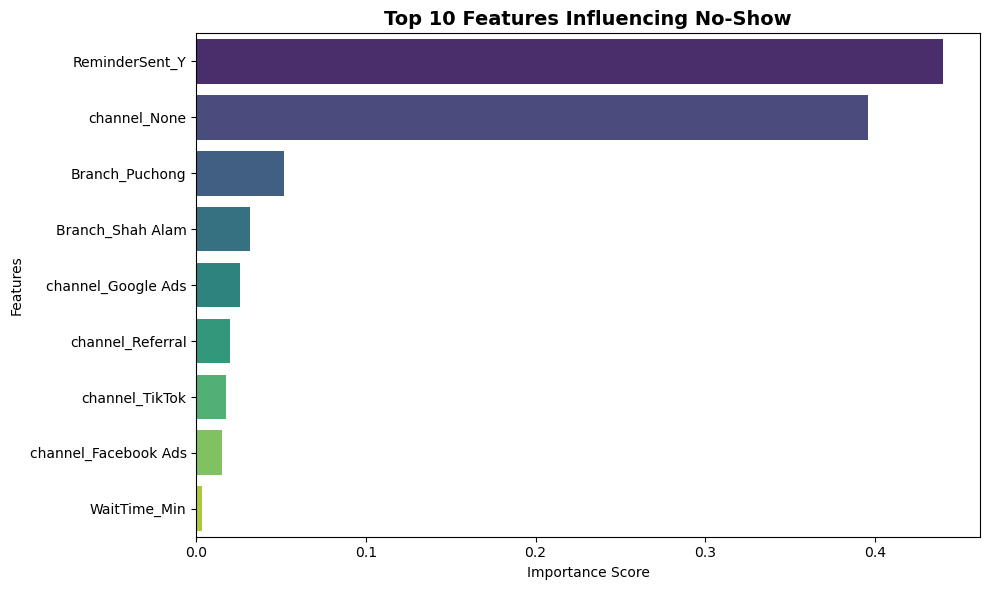

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Extract feature importances from the trained Random Forest model
importances = rf_model.feature_importances_
feature_names = X_train.columns

# 2. Create a DataFrame to hold the features and their importance scores
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

# 3. Sort the DataFrame by importance in descending order
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

# 4. Display the top factors as a table
print("Top Factors Influencing Patient No-Shows:")
display(feature_importance_df.head(10))

# 5. Visualize the Feature Importances using a horizontal bar chart
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df.head(10), palette='viridis')
plt.title('Top 10 Features Influencing No-Show', fontsize=14, fontweight='bold')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()